# Speech -- Text-to-Speech Synthesis
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 5. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Speech -- Text-to-Speech Synthesis](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [2]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [5]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 5. Speech / Audio -- Text-to-Speech Synthesis
### Problem: given raw text, generate a spoken-word audio waveform of someone saying it.

### 5.1 Problem Statement & Why this Architecture

TTS is a **sequence-to-sequence** problem: a short text sequence maps to a much longer audio sequence. Rather than predicting raw waveform samples (tens of thousands per second) directly, we predict an intermediate **mel-spectrogram** -- a compact, perceptually-motivated time-frequency representation -- and then convert that to audio with a vocoder.

We build a simplified **Tacotron-style** model: a convolutional+BiLSTM text encoder, and an autoregressive LSTM decoder with **location-sensitive attention**, which adds a convolution over the *previous* attention weights so the decoder tends to sweep monotonically left-to-right through the text (critical for TTS -- unlike translation, alignment should almost never jump backward). For the vocoder we use **Griffin-Lim** (classic iterative phase estimation) instead of a neural vocoder, trading some audio fidelity for zero extra training.

🔥 **Dataset choice:** we use **CMU ARCTIC** (a single speaker, ~70MB) rather than the more commonly-cited LJSpeech (~2.6GB) -- same task, same architecture, a fraction of the download.

### 5.2 Data Collection & Preparation


In [6]:
import torchaudio
import soundfile as sf

SPEECH_SAMPLE_RATE = 16000  # CMU ARCTIC's native rate -- skip resampling entirely
N_MELS = 80


class CMUArcticLite(Dataset):
    # Minimal CMU ARCTIC reader using soundfile directly. We reuse torchaudio's
    # CMUARCTIC class only to download+extract the archive; its own __getitem__
    # calls torchaudio.load, which in newer torchaudio versions requires the
    # optional `torchcodec` backend -- soundfile sidesteps that dependency.
    def __init__(self, root="data/speech", speaker="bdl", download=True, max_items=100):
        from torchaudio.datasets import CMUARCTIC
        Path(root).mkdir(parents=True, exist_ok=True)  # CMUARCTIC's os.mkdir needs the parent to already exist
        _ = CMUARCTIC(root=root, url=speaker, download=download)
        base = Path(root) / "ARCTIC" / f"cmu_us_{speaker}_arctic"
        pattern = re.compile(r'\( (\S+) "(.*)" \)')
        items = []
        for line in (base / "etc" / "txt.done.data").read_text(encoding="utf-8").splitlines():
            m = pattern.match(line.strip())
            if m:
                items.append((m.group(1), m.group(2)))
        self.items = items[:max_items]
        self.wav_dir = base / "wav"

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        uid, text = self.items[idx]
        data, sr = sf.read(str(self.wav_dir / f"{uid}.wav"), dtype="float32")
        return torch.from_numpy(data).unsqueeze(0), sr, text


speech_ds = CMUArcticLite(max_items=100)
print(f"Loaded {len(speech_ds)} (text, audio) utterance pairs")
wav0, sr0, text0 = speech_ds[0]
print(f"Sample rate: {sr0} | Transcript: {text0}")
play_audio(wav0[0], sr0)


Loaded 100 (text, audio) utterance pairs
Sample rate: 16000 | Transcript: Author of the danger trail, Philip Steels, etc.


In [7]:
SPEECH_CHARS = list(" abcdefghijklmnopqrstuvwxyz.,!?'-")
speech_stoi = {c: i + 1 for i, c in enumerate(SPEECH_CHARS)}  # 0 reserved for padding
SPEECH_VOCAB_SIZE = len(SPEECH_CHARS) + 1


def encode_speech_text(s):
    return [speech_stoi.get(c, speech_stoi[" "]) for c in s.lower() if c in speech_stoi]


mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SPEECH_SAMPLE_RATE, n_fft=1024, hop_length=256, win_length=1024, n_mels=N_MELS
)
amplitude_to_db = torchaudio.transforms.AmplitudeToDB()
MAX_MEL_FRAMES = 150  # crop long utterances so the sequential decoder loop stays fast


def wav_to_mel(waveform):
    mel = mel_transform(waveform)
    mel = amplitude_to_db(mel).squeeze(0)  # [n_mels, T]
    mel = (mel + 100) / 100  # rough normalization to roughly [0, 1]
    return mel[:, :MAX_MEL_FRAMES]


def collate_tts(batch):
    texts, mels = [], []
    for waveform, sr, text in batch:
        texts.append(torch.tensor(encode_speech_text(text)[:MAX_MEL_FRAMES], dtype=torch.long))
        mels.append(wav_to_mel(waveform).transpose(0, 1))  # [T, n_mels]
    text_lens = torch.tensor([len(t) for t in texts])
    mel_lens = torch.tensor([m.shape[0] for m in mels])
    texts_padded = nn.utils.rnn.pad_sequence(texts, batch_first=True)
    mels_padded = nn.utils.rnn.pad_sequence(mels, batch_first=True)
    stop_targets = torch.zeros(mels_padded.shape[0], mels_padded.shape[1])
    for i, l in enumerate(mel_lens):
        stop_targets[i, l - 1:] = 1.0  # a 1 marks "stop generating" from the last real frame onward
    return texts_padded, text_lens, mels_padded, mel_lens, stop_targets


speech_loader = DataLoader(speech_ds, batch_size=8, shuffle=True, collate_fn=collate_tts)


### 5.3 Model Architecture


In [8]:
class TTSEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=96, hidden_dim=96):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.conv = nn.Sequential(nn.Conv1d(embed_dim, embed_dim, 5, padding=2), nn.ReLU(), nn.BatchNorm1d(embed_dim))
        self.lstm = nn.LSTM(embed_dim, hidden_dim // 2, bidirectional=True, batch_first=True)

    def forward(self, text):
        x = self.embed(text).transpose(1, 2)  # [B, C, T]
        x = self.conv(x).transpose(1, 2)       # [B, T, C]
        out, _ = self.lstm(x)
        return out  # [B, T_text, hidden_dim] -- the "memory" attention reads from


class LocationSensitiveAttention(nn.Module):
    # Adds a convolution over the *previous* attention weights so the decoder
    # tends to move monotonically forward through the text -- critical for TTS,
    # where (unlike machine translation) alignment should be roughly left-to-right.
    def __init__(self, query_dim, memory_dim, attn_dim=96, n_filters=16, kernel_size=15):
        super().__init__()
        self.query_proj = nn.Linear(query_dim, attn_dim, bias=False)
        self.memory_proj = nn.Linear(memory_dim, attn_dim, bias=False)
        self.location_conv = nn.Conv1d(1, n_filters, kernel_size, padding=kernel_size // 2, bias=False)
        self.location_proj = nn.Linear(n_filters, attn_dim, bias=False)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, query, memory, prev_attn, mask=None):
        loc = self.location_proj(self.location_conv(prev_attn.unsqueeze(1)).transpose(1, 2))
        scores = self.v(torch.tanh(self.query_proj(query).unsqueeze(1) + self.memory_proj(memory) + loc)).squeeze(-1)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e4)
        weights = torch.softmax(scores, dim=-1)
        context = (weights.unsqueeze(-1) * memory).sum(dim=1)
        return context, weights


class TTSDecoder(nn.Module):
    # Autoregressive: at each step, attend over the text encoding, then predict
    # the next mel frame (and a stop probability) from the attended context.
    def __init__(self, memory_dim=96, n_mels=N_MELS, hidden_dim=128):
        super().__init__()
        self.prenet = nn.Sequential(nn.Linear(n_mels, hidden_dim), nn.ReLU(), nn.Dropout(0.5))
        self.attention = LocationSensitiveAttention(hidden_dim, memory_dim)
        self.lstm = nn.LSTMCell(hidden_dim + memory_dim, hidden_dim)
        self.mel_proj = nn.Linear(hidden_dim + memory_dim, n_mels)
        self.stop_proj = nn.Linear(hidden_dim + memory_dim, 1)
        self.hidden_dim = hidden_dim

    def forward(self, memory, mel_targets=None, max_steps=None, mask=None):
        B, T_mem, _ = memory.shape
        device = memory.device
        h = torch.zeros(B, self.hidden_dim, device=device)
        c = torch.zeros(B, self.hidden_dim, device=device)
        prev_attn = torch.zeros(B, T_mem, device=device)
        prev_mel = torch.zeros(B, self.mel_proj.out_features, device=device)

        steps = mel_targets.shape[1] if mel_targets is not None else max_steps
        mels_out, stops_out, attns_out = [], [], []
        for t in range(steps):
            prenet_out = self.prenet(prev_mel)
            context, attn_w = self.attention(h, memory, prev_attn, mask)
            lstm_in = torch.cat([prenet_out, context], dim=-1)
            h, c = self.lstm(lstm_in, (h, c))
            proj_in = torch.cat([h, context], dim=-1)
            mel_frame = self.mel_proj(proj_in)
            stop_logit = self.stop_proj(proj_in)
            mels_out.append(mel_frame)
            stops_out.append(stop_logit.squeeze(-1))
            attns_out.append(attn_w)
            prev_attn = attn_w
            # Teacher forcing during training; autoregressive feedback at inference.
            prev_mel = mel_targets[:, t] if mel_targets is not None else mel_frame
        return torch.stack(mels_out, dim=1), torch.stack(stops_out, dim=1), torch.stack(attns_out, dim=1)


class TacotronLite(nn.Module):
    def __init__(self, vocab_size, n_mels=N_MELS):
        super().__init__()
        self.encoder = TTSEncoder(vocab_size)
        self.decoder = TTSDecoder(n_mels=n_mels)

    def forward(self, text, mel_targets=None, max_steps=None, text_mask=None):
        memory = self.encoder(text)
        return self.decoder(memory, mel_targets, max_steps, text_mask)


tts_model = TacotronLite(SPEECH_VOCAB_SIZE).to(DEVICE)
count_parameters(tts_model)


TacotronLite: 0.34M trainable parameters


338913

### 5.4 Loss Functions, Optimizers & Training Strategy

Mel MSE loss (predicted vs. true mel frames) plus a binary cross-entropy stop-token loss (learning *when* to stop generating), trained with teacher forcing so the decoder always sees ground-truth previous frames during training.

### 5.5 Training Loop

**Calibrated to ~175s (~3 min) on a CUDA GPU** (20 epochs over 100 utterances) -- this is the most expensive section, since the decoder's per-frame LSTM loop can't be parallelized across time the way attention can.


TTS epoch 1/20:   0%|          | 0/13 [00:00<?, ?it/s]

TTS epoch 1/20:   0%|          | 0/13 [00:01<?, ?it/s, loss=1.5355]

TTS epoch 1/20:   8%|▊         | 1/13 [00:01<00:14,  1.25s/it, loss=1.5355]

TTS epoch 1/20:   8%|▊         | 1/13 [00:01<00:14,  1.25s/it, loss=1.3882]

TTS epoch 1/20:  15%|█▌        | 2/13 [00:01<00:10,  1.09it/s, loss=1.3882]

...

TTS epoch 20/20:  85%|████████▍ | 11/13 [00:08<00:01,  1.40it/s, loss=0.0612]

TTS epoch 20/20:  92%|█████████▏| 12/13 [00:08<00:00,  1.41it/s, loss=0.0612]

TTS epoch 20/20:  92%|█████████▏| 12/13 [00:08<00:00,  1.41it/s, loss=0.0622]

TTS epoch 20/20: 100%|██████████| 13/13 [00:08<00:00,  1.45it/s, loss=0.0622]

TTS epoch 20/20: 100%|██████████| 13/13 [00:08<00:00,  1.45it/s, loss=0.0622]

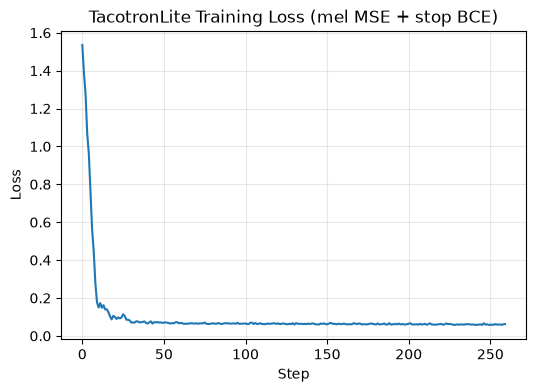

In [9]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
SPEECH_EPOCHS = 20            # calibrated: ~175s on an RTX 2060
SPEECH_CKPT = "checkpoints/speech_tts.pt"


def train_tts(model, loader, epochs=SPEECH_EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    model.train()
    step = 0
    for epoch in range(epochs):
        pbar = tqdm(loader, desc=f"TTS epoch {epoch + 1}/{epochs}")
        for texts, text_lens, mels, mel_lens, stop_targets in pbar:
            texts, mels, stop_targets = texts.to(DEVICE), mels.to(DEVICE), stop_targets.to(DEVICE)
            text_mask = (torch.arange(texts.shape[1])[None, :] < text_lens[:, None]).to(DEVICE)
            mel_pred, stop_pred, _ = model(texts, mel_targets=mels, text_mask=text_mask)

            mel_mask = (torch.arange(mels.shape[1])[None, :] < mel_lens[:, None]).to(DEVICE)
            mel_loss = F.mse_loss(mel_pred[mel_mask], mels[mel_mask])
            stop_loss = F.binary_cross_entropy_with_logits(stop_pred[mel_mask], stop_targets[mel_mask])
            loss = mel_loss + stop_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            history.append(loss.item())
            step += 1
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        save_checkpoint(model, optimizer, step, SPEECH_CKPT)
    return history


speech_history = train_tts(tts_model, speech_loader)
plot_loss(speech_history, title="TacotronLite Training Loss (mel MSE + stop BCE)")


In [10]:
# (b) PRETRAINED / INFERENCE-ONLY PATH ---------------------------------------
# For high-fidelity speech, use a pretrained model + neural vocoder instead of
# Griffin-Lim -- HiFi-GAN removes almost all of the "robotic" phase artifacts.
# (off by default -- downloads ~600MB of model weights)
USE_PRETRAINED_SPEECH = False

if USE_PRETRAINED_SPEECH:
    from transformers import SpeechT5Processor, SpeechT5ForTextToSpeech, SpeechT5HifiGan
    speecht5_processor = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
    speecht5_model = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts").to(DEVICE)
    speecht5_vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").to(DEVICE)


### 5.6 Inference / Generation Function


In [11]:
griffin_lim = torchaudio.transforms.GriffinLim(n_fft=1024, hop_length=256, win_length=1024, power=1.0)
inverse_mel = torchaudio.transforms.InverseMelScale(n_stft=1024 // 2 + 1, n_mels=N_MELS, sample_rate=SPEECH_SAMPLE_RATE)


@torch.no_grad()
def synthesize_speech(model, text, max_steps=200):
    model.eval()
    tokens = torch.tensor([encode_speech_text(text)], dtype=torch.long, device=DEVICE)
    mel_pred, stop_pred, attn = model(tokens, max_steps=max_steps)
    stop_probs = torch.sigmoid(stop_pred[0])
    end = (stop_probs > 0.5).nonzero()
    T = end[0].item() if len(end) > 0 else max_steps
    mel = mel_pred[0, :T]  # [T, n_mels]
    model.train()

    # Invert our normalization, then approximate-invert the mel filterbank + STFT
    # with Griffin-Lim (iterative phase estimation) -- lower fidelity than a
    # neural vocoder but requires no extra training.
    mel_db = mel * 100 - 100
    mel_power = torchaudio.functional.DB_to_amplitude(mel_db, ref=1.0, power=1.0).T.unsqueeze(0)
    linear_spec = inverse_mel(mel_power.cpu())
    waveform = griffin_lim(linear_spec)
    return waveform.squeeze(0), mel.T, attn[0, :T]


### 5.7 Visualization & Results


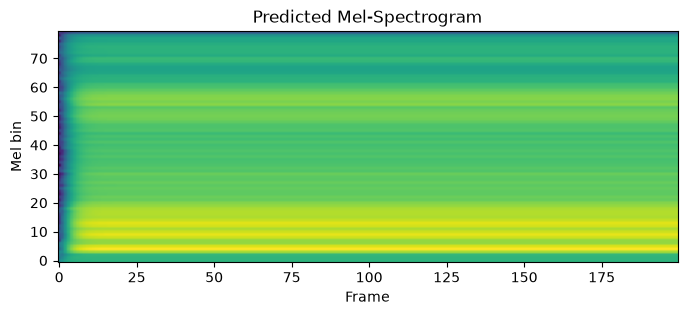

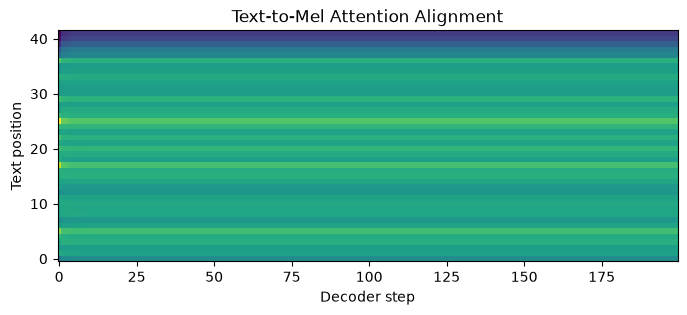

In [12]:
wav, mel_out, attn_out = synthesize_speech(tts_model, "the birch canoe slid on the smooth planks.")

plt.figure(figsize=(8, 3)); plt.imshow(mel_out.cpu(), aspect="auto", origin="lower")
plt.title("Predicted Mel-Spectrogram"); plt.xlabel("Frame"); plt.ylabel("Mel bin"); plt.show()

plt.figure(figsize=(8, 3)); plt.imshow(attn_out.cpu().T, aspect="auto", origin="lower")
plt.title("Text-to-Mel Attention Alignment"); plt.xlabel("Decoder step"); plt.ylabel("Text position"); plt.show()

play_audio(wav, SPEECH_SAMPLE_RATE)


### 5.8 User Input → Output Demo


In [13]:
user_text = "artificial intelligence can generate speech from text"  # <- edit this
wav, mel_out, _ = synthesize_speech(tts_model, user_text)
play_audio(wav, SPEECH_SAMPLE_RATE)


### 5.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** converting arbitrary input text into a spoken audio waveform by learning a monotonic text-to-mel alignment and a mel-to-waveform inversion.
- 💡 **Insight:** the attention alignment plot is the single best training diagnostic for TTS -- a clean, roughly diagonal line means the model has learned to "read" the text in order; a diffuse or broken plot predicts garbled or looping audio.
- ⚠️ **Limitation:** Griffin-Lim reconstructs phase iteratively and imperfectly, giving speech a characteristic robotic/metallic quality no matter how well the mel-predictor is trained. 100 training utterances also isn't enough data to generalize well to words far from the training vocabulary.
- 🚀 **Scaling path:** train on the full CMU ARCTIC speaker (~1,100 utterances) or LJSpeech (~13,100 utterances) for many more epochs, then replace Griffin-Lim with a neural vocoder (HiFi-GAN) for the single biggest quality jump -- or skip straight to the pretrained SpeechT5 + HiFi-GAN pipeline in 5.5(b).


---
## This notebook is part of a series

This model solved the problem of: **converting arbitrary input text into a spoken audio waveform**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
